# 06B — Robust model selection with recording-level separation

## Objective

Notebooks 05 and 06 initially selected models using random **call-level** train/validation splits.
That protocol produced extremely low errors, but the additional robustness check in notebook 06 showed
that performance degraded substantially when complete source WAVs were kept out of the training set.

This notebook therefore repeats model selection under the stricter rule:

> **A source WAV may belong to TRAIN or VALIDATION, never both.**

The goal is to choose the model that generalizes best to **unseen recordings**, rather than the model
that benefits most from recording-specific background, microphone, or acquisition cues.

## Experimental plan

### Stage A — robust feature comparison

Using a minimum target of **12 s of training material per species**, compare:

- 12 MFCC
- 20 MFCC
- 20 PLP-RASTA
- 20 m-FCC

for:

\[
M \in \{2,4,8,16,32,64\}
\]

with 10 reproducible recording-level repetitions.

The feature with the lowest best-achievable mean WER is selected.

### Stage B — robust parameter optimization

For the feature selected in Stage A, test:

\[
6,\ 12,\ 18\ {\rm s}
\]

and:

\[
M \in \{2,4,8,16,32,64\}
\]

again with 10 recording-level repetitions.

## Paper versus this project

`[PAPER]`

The article reports **20 m-FCC** as its preferred representation and ultimately uses a high-order
GMM configuration (`M = 64`). The paper's train/validation description is based on selected call
segments and does not report this recording-level grouped validation control.

`[ROBUSTNESS EXTENSION]`

This notebook adds recording-level separation because our recovered corpus showed a strong difference
between call-level and recording-level validation.

We therefore keep the published result as the reference, but choose our final model from the stricter
recording-level experiment.

## Important consequence of grouping by WAV

Because an entire WAV is assigned as one unit, the requested 6/12/18 seconds are **minimum target
durations**, not exact durations. Some species will necessarily overshoot the target substantially.

Every result therefore records the actual training duration and the number of training/validation WAVs.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.stats import t as student_t
from sklearn.cluster import kmeans_plusplus
from sklearn.exceptions import ConvergenceWarning
from sklearn.mixture import GaussianMixture

pd.set_option("display.width", 190)
pd.set_option("display.max_rows", 180)
pd.set_option("display.max_columns", 90)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = REPO_ROOT / "data" / "processed"

CALLS_PATH = PROCESSED_DIR / "calls.csv"

FEATURE_COMPARISON_DIR = (
    PROCESSED_DIR / "feature_comparison"
)

FEATURE_CACHE_PATH = (
    FEATURE_COMPARISON_DIR
    / "call_feature_sets.joblib"
)

PREVIOUS_FINAL_SELECTION_DIR = (
    PROCESSED_DIR / "final_model_selection"
)

PREVIOUS_RECORDING_SUMMARY_PATH = (
    PREVIOUS_FINAL_SELECTION_DIR
    / "recording_level_summary.csv"
)

RESULTS_DIR = (
    PROCESSED_DIR / "robust_model_selection"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if not CALLS_PATH.exists():
    raise FileNotFoundError(
        f"Missing {CALLS_PATH}. Run notebook 02 first."
    )

if not FEATURE_CACHE_PATH.exists():
    raise FileNotFoundError(
        f"Missing {FEATURE_CACHE_PATH}. "
        "Run notebook 05_feature_comparison first."
    )

print("Repository root :", REPO_ROOT)
print("calls.csv       :", CALLS_PATH)
print("Feature cache   :", FEATURE_CACHE_PATH)
print("Results         :", RESULTS_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
calls.csv       : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\calls.csv
Feature cache   : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\feature_comparison\call_feature_sets.joblib
Results         : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\robust_model_selection


## 2. Load calls and the four cached feature representations

Notebook 05 already extracted all four representations call by call and saved them in
`call_feature_sets.joblib`.

This notebook reuses that cache. Therefore the only methodological change is **how complete recordings
are separated into training and validation**.

In [2]:
calls = (
    pd.read_csv(CALLS_PATH)
    .copy()
    .reset_index(drop=True)
)

required_columns = {
    "code",
    "species",
    "wav",
    "seconds",
}

missing = (
    required_columns
    - set(calls.columns)
)

if missing:
    raise ValueError(
        f"calls.csv is missing required columns: {sorted(missing)}"
    )

calls["call_id"] = [
    f"call_{i:04d}"
    for i in range(len(calls))
]

# Normalized recording group.
# Using the WAV basename is conservative: if identical basenames happened
# to refer to different files, they would be kept together rather than leaked.
calls["recording_group"] = (
    calls["wav"]
    .astype(str)
    .str.strip()
    .str.lower()
)

CALLS_BY_ID = (
    calls.set_index(
        "call_id",
        drop=False,
    )
)

CALL_FEATURES = joblib.load(
    FEATURE_CACHE_PATH
)

FEATURE_NAMES = (
    "12_MFCC",
    "20_MFCC",
    "20_PLP_RASTA",
    "20_mFCC",
)

EXPECTED_DIMS = {
    "12_MFCC": 12,
    "20_MFCC": 20,
    "20_PLP_RASTA": 20,
    "20_mFCC": 20,
}

expected_call_ids = set(
    calls["call_id"]
)

cache_call_ids = set(
    CALL_FEATURES
)

if expected_call_ids != cache_call_ids:
    raise RuntimeError(
        "Feature cache and calls.csv do not contain the same call IDs."
    )

bad_features = []

for call_id in calls["call_id"]:

    feature_sets = CALL_FEATURES[
        call_id
    ]

    for feature_name in FEATURE_NAMES:

        if feature_name not in feature_sets:
            bad_features.append(
                (call_id, feature_name, "missing")
            )
            continue

        X = np.asarray(
            feature_sets[
                feature_name
            ]
        )

        expected_dim = EXPECTED_DIMS[
            feature_name
        ]

        valid = (
            X.ndim == 2
            and X.shape[1] == expected_dim
            and len(X) > 0
            and np.isfinite(X).all()
        )

        if not valid:
            bad_features.append(
                (
                    call_id,
                    feature_name,
                    X.shape,
                )
            )

if bad_features:
    raise RuntimeError(
        f"Invalid cached feature matrices: {bad_features[:10]}"
    )

print("Calls              :", len(calls))
print("Recording groups   :", calls["recording_group"].nunique())
print("Feature sets       :", FEATURE_NAMES)
print("Feature-cache check: OK")

Calls              : 1461
Recording groups   : 66
Feature sets       : ('12_MFCC', '20_MFCC', '20_PLP_RASTA', '20_mFCC')
Feature-cache check: OK


## 3. Species and recording inventory

A recording-level experiment is only meaningful if each class has multiple independent source WAVs.

`f09` remains excluded because the recovered corpus contains too little labelled material.

The number of WAVs per species is also important for interpretation. A species represented by only a
few recordings can have a much less stable generalization estimate, even if it contains many individual
calls.

In [3]:
species_inventory = (
    calls.groupby(
        ["code", "species"],
        as_index=False,
    )
    .agg(
        n_calls=("call_id", "size"),
        total_seconds=("seconds", "sum"),
        n_recordings=(
            "recording_group",
            "nunique",
        ),
    )
    .sort_values("code")
)

USABLE_CODES = tuple(
    species_inventory.loc[
        (
            species_inventory[
                "total_seconds"
            ] > 18
        )
        & (
            species_inventory[
                "code"
            ] != "f09"
        ),
        "code",
    ]
)

species_inventory["used"] = (
    species_inventory["code"]
    .isin(USABLE_CODES)
)

display(
    species_inventory.round(3)
)

usable_inventory = (
    species_inventory[
        species_inventory["used"]
    ]
)

if (
    usable_inventory[
        "n_recordings"
    ] < 2
).any():
    raise RuntimeError(
        "At least one usable species has fewer than two source recordings."
    )

print("Usable classes:", USABLE_CODES)
print("Number of classes:", len(USABLE_CODES))

,code,species,n_calls,total_seconds,n_recordings,used
0,f01,Boana alfaroi,98,44.72,5,True
1,f02,Dendropsophus bifurcus,99,41.72,10,True
2,f03,Boana cinerascens,169,102.58,8,True
3,f04,Pristimantis conspicillatus,186,77.94,9,True
4,f05,Leptodactylus discodactylus,340,114.36,3,True
5,f06,Osteocephalus fuscifacies,54,24.94,5,True
6,f07,Boana lanciformis,101,57.84,7,True
7,f08,Rhinella margaritifera,96,102.66,7,True
8,f09,Dendropsophus parviceps,2,1.18,1,False
9,f10,Engystomops petersi,316,134.00,12,True


Usable classes: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')
Number of classes: 9


## 4. Experiment configuration

In [4]:
FEATURE_COMPARISON_SECONDS = 12

TRAINING_DURATIONS = (
    6,
    12,
    18,
)

N_COMPONENTS_GRID = (
    2,
    4,
    8,
    16,
    32,
    64,
)

N_REPEATS = 10

BASE_SEED = 20260814

# Number of randomized candidate WAV assignments considered for each split.
# The best valid candidate is selected by minimum duration overshoot.
SPLIT_SEARCH_ATTEMPTS = 1500

RUN_STAGE_A = True
RUN_STAGE_B = True

STORE_CALL_PREDICTIONS = True

print(
    "Stage A conditions:",
    len(FEATURE_NAMES)
    * len(N_COMPONENTS_GRID)
    * N_REPEATS,
)

print(
    "Stage B grid conditions before reusing 12-s Stage A:",
    len(TRAINING_DURATIONS)
    * len(N_COMPONENTS_GRID)
    * N_REPEATS,
)

Stage A conditions: 240
Stage B grid conditions before reusing 12-s Stage A: 180


## 5. Global recording-level split

The split is built **globally across the full usable corpus**, not independently for each species.

That detail matters because one physical recording could contain annotations associated with more than
one species. A recording assigned to TRAIN is therefore TRAIN everywhere.

### Split constraints

For every repetition:

- `TRAIN recordings ∩ VALIDATION recordings = ∅`;
- every species has at least the requested minimum training duration;
- every species retains at least one validation call;
- every species retains at least one validation recording.

### Overshoot control

Whole recordings can make the training duration exceed the target. Rather than accepting the first
valid random split, the code evaluates many reproducible candidate assignments and keeps the valid one
with the smallest normalized total duration overshoot.

This does not make the grouped split identical to the paper's duration-controlled call split. It simply
makes the robustness experiment less arbitrary.

In [5]:
USABLE_CALLS = (
    calls[
        calls["code"].isin(
            USABLE_CODES
        )
    ]
    .copy()
    .reset_index(drop=True)
)

ALL_RECORDINGS = np.array(
    sorted(
        USABLE_CALLS[
            "recording_group"
        ].unique()
    ),
    dtype=object,
)

RECORDING_SPECIES_SECONDS = (
    USABLE_CALLS
    .groupby(
        [
            "recording_group",
            "code",
        ]
    )["seconds"]
    .sum()
    .unstack(
        fill_value=0.0
    )
    .reindex(
        columns=USABLE_CODES,
        fill_value=0.0,
    )
)


def evaluate_recording_assignment(
    train_recordings,
    target_seconds,
):
    train_recordings = set(
        train_recordings
    )

    validation_recordings = (
        set(ALL_RECORDINGS)
        - train_recordings
    )

    if not train_recordings:
        return None

    if not validation_recordings:
        return None

    if not train_recordings.isdisjoint(
        validation_recordings
    ):
        raise AssertionError(
            "Global recording leakage detected."
        )

    split = {}
    overshoot_score = 0.0

    for code in USABLE_CODES:

        species_calls = (
            USABLE_CALLS[
                USABLE_CALLS[
                    "code"
                ] == code
            ]
        )

        train_rows = (
            species_calls[
                species_calls[
                    "recording_group"
                ].isin(
                    train_recordings
                )
            ]
        )

        validation_rows = (
            species_calls[
                species_calls[
                    "recording_group"
                ].isin(
                    validation_recordings
                )
            ]
        )

        if train_rows.empty:
            return None

        if validation_rows.empty:
            return None

        actual_seconds = float(
            train_rows[
                "seconds"
            ].sum()
        )

        if actual_seconds < target_seconds:
            return None

        train_groups = set(
            train_rows[
                "recording_group"
            ]
        )

        validation_groups = set(
            validation_rows[
                "recording_group"
            ]
        )

        if not train_groups.isdisjoint(
            validation_groups
        ):
            raise AssertionError(
                f"Recording leakage for {code}."
            )

        if len(validation_groups) < 1:
            return None

        train_ids = tuple(
            train_rows[
                "call_id"
            ]
        )

        validation_ids = tuple(
            validation_rows[
                "call_id"
            ]
        )

        if not set(
            train_ids
        ).isdisjoint(
            validation_ids
        ):
            raise AssertionError(
                f"Call leakage for {code}."
            )

        overshoot = (
            actual_seconds
            - target_seconds
        )

        overshoot_score += (
            overshoot
            / target_seconds
        )

        split[code] = {
            "code": code,
            "target_seconds": target_seconds,
            "actual_seconds": actual_seconds,
            "overshoot_seconds": overshoot,
            "train_ids": train_ids,
            "validation_ids": validation_ids,
            "n_train_recordings": len(
                train_groups
            ),
            "n_validation_recordings": len(
                validation_groups
            ),
        }

    # A small secondary preference for fewer training recordings.
    score = (
        overshoot_score,
        len(train_recordings),
    )

    return {
        "split": split,
        "train_recordings": train_recordings,
        "validation_recordings": validation_recordings,
        "score": score,
    }


def build_recording_level_split(
    target_seconds,
    repeat,
    n_attempts=SPLIT_SEARCH_ATTEMPTS,
):
    seed = (
        BASE_SEED
        + 70_000_000
        + repeat * 100_000
        + target_seconds * 100
    )

    best = None

    for attempt in range(
        n_attempts
    ):
        rng = np.random.default_rng(
            seed + attempt
        )

        order = rng.permutation(
            ALL_RECORDINGS
        )

        train_recordings = set()

        accumulated = {
            code: 0.0
            for code in USABLE_CODES
        }

        for recording in order:

            contribution = (
                RECORDING_SPECIES_SECONDS
                .loc[recording]
            )

            useful = any(
                (
                    accumulated[code]
                    < target_seconds
                )
                and (
                    float(
                        contribution.get(
                            code,
                            0.0,
                        )
                    ) > 0
                )
                for code in USABLE_CODES
            )

            if not useful:
                continue

            train_recordings.add(
                str(recording)
            )

            for code in USABLE_CODES:
                accumulated[code] += float(
                    contribution.get(
                        code,
                        0.0,
                    )
                )

            if all(
                accumulated[code]
                >= target_seconds
                for code in USABLE_CODES
            ):
                break

        candidate = (
            evaluate_recording_assignment(
                train_recordings=train_recordings,
                target_seconds=target_seconds,
            )
        )

        if candidate is None:
            continue

        candidate["attempt"] = attempt
        candidate["seed"] = seed + attempt

        if (
            best is None
            or candidate["score"]
            < best["score"]
        ):
            best = candidate

    if best is None:
        raise RuntimeError(
            "Could not construct a valid recording-level split "
            f"for target={target_seconds}s, repeat={repeat}."
        )

    return best

## 6. Precompute and audit all grouped splits

The exact split for each `duration × repeat` is generated once and reused everywhere.

This guarantees that feature representations and GMM orders are compared on the same recordings.

In [6]:
ROBUST_SPLITS = {}
split_audit_rows = []

for target_seconds in TRAINING_DURATIONS:

    for repeat in range(
        N_REPEATS
    ):
        result = (
            build_recording_level_split(
                target_seconds=target_seconds,
                repeat=repeat,
            )
        )

        ROBUST_SPLITS[
            (
                target_seconds,
                repeat,
            )
        ] = result

        train_recordings = (
            result[
                "train_recordings"
            ]
        )

        validation_recordings = (
            result[
                "validation_recordings"
            ]
        )

        assert train_recordings.isdisjoint(
            validation_recordings
        )

        for code in USABLE_CODES:

            info = (
                result[
                    "split"
                ][code]
            )

            split_audit_rows.append({
                "training_seconds_target":
                    target_seconds,
                "repeat":
                    repeat,
                "code":
                    code,
                "training_seconds_actual":
                    info[
                        "actual_seconds"
                    ],
                "overshoot_seconds":
                    info[
                        "overshoot_seconds"
                    ],
                "n_train_calls":
                    len(
                        info[
                            "train_ids"
                        ]
                    ),
                "n_validation_calls":
                    len(
                        info[
                            "validation_ids"
                        ]
                    ),
                "n_train_recordings":
                    info[
                        "n_train_recordings"
                    ],
                "n_validation_recordings":
                    info[
                        "n_validation_recordings"
                    ],
                "global_train_recordings":
                    len(
                        train_recordings
                    ),
                "global_validation_recordings":
                    len(
                        validation_recordings
                    ),
                "split_search_attempt":
                    result[
                        "attempt"
                    ],
            })

split_audit = pd.DataFrame(
    split_audit_rows
)

print(
    "Precomputed grouped splits:",
    len(ROBUST_SPLITS),
)

display(
    split_audit
    .groupby(
        [
            "training_seconds_target",
            "code",
        ],
        as_index=False,
    )
    .agg(
        actual_seconds_mean=(
            "training_seconds_actual",
            "mean",
        ),
        actual_seconds_min=(
            "training_seconds_actual",
            "min",
        ),
        actual_seconds_max=(
            "training_seconds_actual",
            "max",
        ),
        train_recordings_mean=(
            "n_train_recordings",
            "mean",
        ),
        validation_recordings_mean=(
            "n_validation_recordings",
            "mean",
        ),
    )
    .round(3)
)

Precomputed grouped splits: 30


,training_seconds_target,code,actual_seconds_mean,actual_seconds_min,actual_seconds_max,train_recordings_mean,validation_recordings_mean
0,6,f01,8.740,8.18,10.22,1.0,4.0
1,6,f02,8.076,6.02,13.58,2.2,7.8
2,6,f03,8.504,7.70,15.50,1.2,6.8
3,6,f04,9.470,7.00,13.84,1.2,7.8
4,6,f05,7.520,7.52,7.52,1.0,2.0
5,6,f06,7.030,6.00,8.70,1.2,3.8
6,6,f07,7.388,6.92,9.34,1.0,6.0
7,6,f08,12.008,11.20,15.28,1.0,6.0
8,6,f10,7.452,6.92,8.32,1.1,10.9
9,12,f01,17.184,16.66,18.40,2.0,3.0


## 7. Split diversity diagnostic

A species with only a handful of independent recordings cannot support unlimited distinct grouped
partitions.

This diagnostic reports how many distinct **global training-recording sets** were obtained across the
ten repetitions for each target duration.

In [7]:
split_diversity_rows = []

for target_seconds in TRAINING_DURATIONS:

    signatures = []

    for repeat in range(
        N_REPEATS
    ):
        train_recordings = (
            ROBUST_SPLITS[
                (
                    target_seconds,
                    repeat,
                )
            ][
                "train_recordings"
            ]
        )

        signatures.append(
            tuple(
                sorted(
                    train_recordings
                )
            )
        )

    split_diversity_rows.append({
        "training_seconds_target":
            target_seconds,
        "n_repeats":
            N_REPEATS,
        "unique_global_train_sets":
            len(
                set(signatures)
            ),
    })

split_diversity = pd.DataFrame(
    split_diversity_rows
)

display(
    split_diversity
)

,training_seconds_target,n_repeats,unique_global_train_sets
0,6,10,10
1,12,10,10
2,18,10,10


## 8. Generic GMM implementation

The GMM implementation remains aligned with notebooks 03, 05 and 06:

- diagonal covariance;
- k-means++ initial means;
- uniform initial weights;
- feature-wise variance initialization;
- one EM initialization;
- complete-call mean log-likelihood classification.

In [8]:
def feature_index(
    feature_name,
):
    return FEATURE_NAMES.index(
        feature_name
    )


def species_number(
    code,
):
    digits = "".join(
        ch
        for ch in str(code)
        if ch.isdigit()
    )

    return int(
        digits
    ) if digits else 0


def stack_features(
    call_ids,
    feature_name,
):
    return np.vstack([
        np.asarray(
            CALL_FEATURES[
                call_id
            ][
                feature_name
            ]
        )
        for call_id in call_ids
    ])


def make_initial_parameters(
    X,
    n_components,
    seed,
):
    if len(X) < n_components:
        raise ValueError(
            f"Only {len(X)} frames available for M={n_components}."
        )

    means_init, _ = (
        kmeans_plusplus(
            X,
            n_clusters=n_components,
            random_state=seed,
        )
    )

    variance = np.maximum(
        np.var(
            X,
            axis=0,
            ddof=0,
        ),
        1e-12,
    )

    weights_init = np.full(
        n_components,
        1.0 / n_components,
    )

    precisions_init = np.tile(
        1.0 / variance,
        (
            n_components,
            1,
        ),
    )

    return (
        weights_init,
        means_init,
        precisions_init,
    )


def fit_gmm(
    X,
    n_components,
    seed,
):
    (
        weights_init,
        means_init,
        precisions_init,
    ) = make_initial_parameters(
        X,
        n_components,
        seed,
    )

    model = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        weights_init=weights_init,
        means_init=means_init,
        precisions_init=precisions_init,
        n_init=1,
        random_state=seed,
        reg_covar=1e-6,
        max_iter=100,
        tol=1e-3,
        init_params="random",
    )

    with warnings.catch_warnings():
        warnings.simplefilter(
            "always",
            ConvergenceWarning,
        )

        model.fit(
            X
        )

    return model


def model_seed(
    repeat,
    n_components,
    code,
    feature_name,
):
    return (
        BASE_SEED
        + repeat * 1_000_000
        + n_components * 1000
        + species_number(code) * 10
        + feature_index(
            feature_name
        )
    )

## 9. Evaluate one feature / duration / GMM condition

In [9]:
def run_feature_condition(
    feature_name,
    target_seconds,
    n_components,
    repeat,
):
    split_result = (
        ROBUST_SPLITS[
            (
                target_seconds,
                repeat,
            )
        ]
    )

    split = (
        split_result[
            "split"
        ]
    )

    models = {}

    for code in USABLE_CODES:

        X_train = stack_features(
            split[code][
                "train_ids"
            ],
            feature_name,
        )

        seed = model_seed(
            repeat=repeat,
            n_components=n_components,
            code=code,
            feature_name=feature_name,
        )

        models[code] = fit_gmm(
            X=X_train,
            n_components=n_components,
            seed=seed,
        )

    per_species_rows = []
    prediction_rows = []

    for true_code in USABLE_CODES:

        validation_ids = (
            split[
                true_code
            ][
                "validation_ids"
            ]
        )

        correct = 0

        for call_id in validation_ids:

            X_call = np.asarray(
                CALL_FEATURES[
                    call_id
                ][
                    feature_name
                ]
            )

            scores = {
                code: float(
                    model.score_samples(
                        X_call
                    ).mean()
                )
                for code, model
                in models.items()
            }

            predicted_code = max(
                scores,
                key=scores.get,
            )

            is_correct = (
                predicted_code
                == true_code
            )

            correct += int(
                is_correct
            )

            prediction_rows.append({
                "feature":
                    feature_name,
                "training_seconds_target":
                    target_seconds,
                "n_components":
                    n_components,
                "repeat":
                    repeat,
                "call_id":
                    call_id,
                "true_code":
                    true_code,
                "predicted_code":
                    predicted_code,
                "correct":
                    is_correct,
                "winning_score":
                    scores[
                        predicted_code
                    ],
                "true_model_score":
                    scores[
                        true_code
                    ],
            })

        n_validation = len(
            validation_ids
        )

        incorrect = (
            n_validation
            - correct
        )

        info = split[
            true_code
        ]

        per_species_rows.append({
            "feature":
                feature_name,
            "training_seconds_target":
                target_seconds,
            "training_seconds_actual":
                info[
                    "actual_seconds"
                ],
            "n_components":
                n_components,
            "repeat":
                repeat,
            "code":
                true_code,
            "species":
                CALLS_BY_ID.loc[
                    validation_ids[0],
                    "species",
                ],
            "n_train_calls":
                len(
                    info[
                        "train_ids"
                    ]
                ),
            "n_validation_calls":
                n_validation,
            "n_train_recordings":
                info[
                    "n_train_recordings"
                ],
            "n_validation_recordings":
                info[
                    "n_validation_recordings"
                ],
            "correct":
                correct,
            "incorrect":
                incorrect,
            "error_rate":
                incorrect
                / n_validation,
        })

    per_species = pd.DataFrame(
        per_species_rows
    )

    predictions = pd.DataFrame(
        prediction_rows
    )

    wer = float(
        per_species[
            "error_rate"
        ].mean()
    )

    return (
        per_species,
        predictions,
        wer,
    )

# Stage A — robust feature comparison

## 10. Compare all four feature representations at a 12-second minimum target

All four features receive the **same recording-level split** for a given repetition and the same
validation calls for a given species.

The feature comparison therefore cannot be explained by one representation receiving an easier set of
recordings than another.

In [10]:
stage_a_wer_rows = []
stage_a_species_blocks = []
stage_a_prediction_blocks = []

if RUN_STAGE_A:

    for repeat in range(
        N_REPEATS
    ):

        print(
            f"Stage A | repeat {repeat + 1:>2}/{N_REPEATS}"
        )

        for feature_name in FEATURE_NAMES:

            for n_components in N_COMPONENTS_GRID:

                (
                    per_species,
                    predictions,
                    wer,
                ) = run_feature_condition(
                    feature_name=feature_name,
                    target_seconds=FEATURE_COMPARISON_SECONDS,
                    n_components=n_components,
                    repeat=repeat,
                )

                stage_a_species_blocks.append(
                    per_species
                )

                if STORE_CALL_PREDICTIONS:
                    stage_a_prediction_blocks.append(
                        predictions
                    )

                stage_a_wer_rows.append({
                    "feature":
                        feature_name,
                    "training_seconds_target":
                        FEATURE_COMPARISON_SECONDS,
                    "n_components":
                        n_components,
                    "repeat":
                        repeat,
                    "WER":
                        wer,
                    "WER_percent":
                        wer * 100,
                })

    stage_a_wer = pd.DataFrame(
        stage_a_wer_rows
    )

    stage_a_per_species = pd.concat(
        stage_a_species_blocks,
        ignore_index=True,
    )

    if STORE_CALL_PREDICTIONS:
        stage_a_predictions = pd.concat(
            stage_a_prediction_blocks,
            ignore_index=True,
        )

    print(
        "Stage A conditions completed:",
        len(stage_a_wer),
    )

    stage_a_wer.to_csv(
        RESULTS_DIR
        / "stage_a_feature_wer_by_repeat.csv",
        index=False,
    )

Stage A | repeat  1/10
Stage A | repeat  2/10
Stage A | repeat  3/10
Stage A | repeat  4/10
Stage A | repeat  5/10
Stage A | repeat  6/10
Stage A | repeat  7/10
Stage A | repeat  8/10
Stage A | repeat  9/10
Stage A | repeat 10/10
Stage A conditions completed: 240


## 11. Stage-A WER summary

In [22]:
def summarize_wer(
    wer_table,
    group_columns,
):
    summary = (
        wer_table
        .groupby(
            group_columns,
            as_index=False,
        )
        .agg(
            WER_mean=(
                "WER",
                "mean",
            ),
            WER_std=(
                "WER",
                "std",
            ),
            WER_min=(
                "WER",
                "min",
            ),
            WER_max=(
                "WER",
                "max",
            ),
            n_repeats=(
                "WER",
                "size",
            ),
        )
    )

    summary["WER_se"] = (
        summary[
            "WER_std"
        ]
        / np.sqrt(
            summary[
                "n_repeats"
            ]
        )
    )

    critical_values = student_t.ppf(
        0.975,
        df=summary[
            "n_repeats"
        ] - 1,
    )

    summary["CI95_low"] = (
        summary[
            "WER_mean"
        ]
        - critical_values
        * summary[
            "WER_se"
        ]
    )

    summary["CI95_high"] = (
        summary[
            "WER_mean"
        ]
        + critical_values
        * summary[
            "WER_se"
        ]
    )

    for column in (
        "WER_mean",
        "WER_std",
        "WER_se",
        "WER_min",
        "WER_max",
        "CI95_low",
        "CI95_high",
    ):
        summary[
            f"{column}_percent"
        ] = (
            summary[
                column
            ]
            * 100
        )

    return summary


if RUN_STAGE_A:

    stage_a_summary = summarize_wer(
        stage_a_wer,
        [
            "feature",
            "n_components",
        ],
    )

    display(
        stage_a_summary[
            [
                "feature",
                "n_components",
                "WER_mean_percent",
                "WER_std_percent",
                "WER_se_percent",
                "CI95_low_percent",
                "CI95_high_percent",
            ]
        ].round(4)
    )

,feature,n_components,WER_mean_percent,WER_std_percent,WER_se_percent,CI95_low_percent,CI95_high_percent
0,12_MFCC,2,39.8956,5.9082,1.8684,35.6691,44.1221
1,12_MFCC,4,45.1257,5.4470,1.7225,41.2292,49.0223
2,12_MFCC,8,46.2281,4.9992,1.5809,42.6519,49.8043
3,12_MFCC,16,50.2329,3.6223,1.1455,47.6417,52.8242
4,12_MFCC,32,52.0722,4.2462,1.3428,49.0347,55.1097
5,12_MFCC,64,47.7871,3.7638,1.1902,45.0946,50.4796
6,20_MFCC,2,39.8175,5.2075,1.6468,36.0923,43.5428
7,20_MFCC,4,43.7354,3.7310,1.1798,41.0664,46.4044
8,20_MFCC,8,45.5218,6.0115,1.9010,41.2215,49.8222
9,20_MFCC,16,46.8801,3.9467,1.2481,44.0568,49.7034


## 12. Recording-level feature curves

This is the robustness analogue of notebook 05's Figure-9-style comparison.

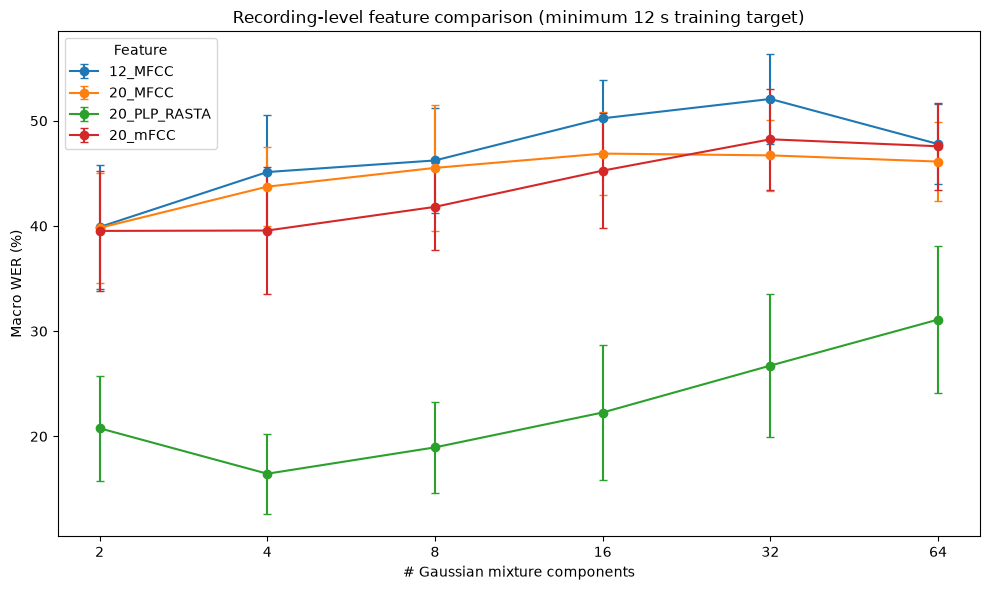

In [23]:
if RUN_STAGE_A:

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    for feature_name in FEATURE_NAMES:

        subset = (
            stage_a_summary[
                stage_a_summary[
                    "feature"
                ] == feature_name
            ]
            .sort_values(
                "n_components"
            )
        )

        ax.errorbar(
            subset[
                "n_components"
            ],
            subset[
                "WER_mean_percent"
            ],
            yerr=subset[
                "WER_std_percent"
            ],
            marker="o",
            capsize=3,
            label=feature_name,
        )

    ax.set_xscale(
        "log",
        base=2,
    )

    ax.set_xticks(
        N_COMPONENTS_GRID
    )

    ax.set_xticklabels(
        [
            str(M)
            for M in N_COMPONENTS_GRID
        ]
    )

    ax.set(
        title=(
            "Recording-level feature comparison "
            "(minimum 12 s training target)"
        ),
        xlabel="# Gaussian mixture components",
        ylabel="Macro WER (%)",
    )

    ax.legend(
        title="Feature"
    )

    plt.tight_layout()
    plt.show()

## 13. Select the robust feature

For each feature, find its best-achievable mean WER across the six GMM orders.

The **robust feature winner** is the representation with the smallest of those best-achievable mean
WER values.

This is deliberately separated from the next stage: after choosing the feature, duration and GMM order
are optimized again under recording-level separation.

In [24]:
if RUN_STAGE_A:

    best_per_feature = (
        stage_a_summary
        .sort_values(
            [
                "feature",
                "WER_mean",
                "WER_std",
                "n_components",
            ]
        )
        .groupby(
            "feature",
            as_index=False,
        )
        .first()
        .sort_values(
            [
                "WER_mean",
                "WER_std",
                "n_components",
            ]
        )
        .reset_index(drop=True)
    )

    display(
        best_per_feature[
            [
                "feature",
                "n_components",
                "WER_mean_percent",
                "WER_std_percent",
                "WER_se_percent",
            ]
        ].round(4)
    )

    robust_feature_row = (
        best_per_feature
        .iloc[0]
    )

    ROBUST_FEATURE = str(
        robust_feature_row[
            "feature"
        ]
    )

    ROBUST_FEATURE_STAGE_A_M = int(
        robust_feature_row[
            "n_components"
        ]
    )

    print(
        "Robust feature winner:",
        ROBUST_FEATURE,
    )

    print(
        "Best Stage-A M:",
        ROBUST_FEATURE_STAGE_A_M,
    )

    print(
        "Stage-A mean WER:",
        round(
            float(
                robust_feature_row[
                    "WER_mean_percent"
                ]
            ),
            4,
        ),
        "%",
    )

,feature,n_components,WER_mean_percent,WER_std_percent,WER_se_percent
0,20_PLP_RASTA,4,16.4503,3.7851,1.1969
1,20_mFCC,2,39.5299,5.6912,1.7997
2,20_MFCC,2,39.8175,5.2075,1.6468
3,12_MFCC,2,39.8956,5.9082,1.8684


Robust feature winner: 20_PLP_RASTA
Best Stage-A M: 4
Stage-A mean WER: 16.4503 %


# Stage B — robust parameter optimization

## 14. Optimize 6/12/18 seconds and GMM order for the robust feature

The 12-second conditions for the winning feature already exist in Stage A and are reused rather than
refitted.

Only the 6-second and 18-second conditions require new GMM fits.

In [25]:
stage_b_wer_rows = []
stage_b_species_blocks = []
stage_b_prediction_blocks = []

if RUN_STAGE_B:

    if not RUN_STAGE_A:
        raise RuntimeError(
            "Stage B needs Stage A to identify ROBUST_FEATURE."
        )

    # Reuse all 12-s results for the selected feature.
    reused_12_wer = (
        stage_a_wer[
            stage_a_wer[
                "feature"
            ] == ROBUST_FEATURE
        ]
        .copy()
    )

    reused_12_species = (
        stage_a_per_species[
            stage_a_per_species[
                "feature"
            ] == ROBUST_FEATURE
        ]
        .copy()
    )

    stage_b_wer_rows.extend(
        reused_12_wer
        .to_dict(
            orient="records"
        )
    )

    stage_b_species_blocks.append(
        reused_12_species
    )

    if STORE_CALL_PREDICTIONS:

        reused_12_predictions = (
            stage_a_predictions[
                stage_a_predictions[
                    "feature"
                ] == ROBUST_FEATURE
            ]
            .copy()
        )

        stage_b_prediction_blocks.append(
            reused_12_predictions
        )

    for target_seconds in (
        6,
        18,
    ):

        for repeat in range(
            N_REPEATS
        ):

            print(
                f"Stage B | feature={ROBUST_FEATURE} | "
                f"target={target_seconds:>2}s | "
                f"repeat={repeat + 1:>2}/{N_REPEATS}"
            )

            for n_components in N_COMPONENTS_GRID:

                (
                    per_species,
                    predictions,
                    wer,
                ) = run_feature_condition(
                    feature_name=ROBUST_FEATURE,
                    target_seconds=target_seconds,
                    n_components=n_components,
                    repeat=repeat,
                )

                stage_b_species_blocks.append(
                    per_species
                )

                if STORE_CALL_PREDICTIONS:
                    stage_b_prediction_blocks.append(
                        predictions
                    )

                stage_b_wer_rows.append({
                    "feature":
                        ROBUST_FEATURE,
                    "training_seconds_target":
                        target_seconds,
                    "n_components":
                        n_components,
                    "repeat":
                        repeat,
                    "WER":
                        wer,
                    "WER_percent":
                        wer * 100,
                })

    stage_b_wer = pd.DataFrame(
        stage_b_wer_rows
    )

    stage_b_per_species = pd.concat(
        stage_b_species_blocks,
        ignore_index=True,
    )

    if STORE_CALL_PREDICTIONS:
        stage_b_predictions = pd.concat(
            stage_b_prediction_blocks,
            ignore_index=True,
        )

    print(
        "Stage B conditions completed:",
        len(stage_b_wer),
    )

    stage_b_wer.to_csv(
        RESULTS_DIR
        / "stage_b_parameter_wer_by_repeat.csv",
        index=False,
    )

Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 1/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 2/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 3/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 4/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 5/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 6/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 7/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 8/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat= 9/10
Stage B | feature=20_PLP_RASTA | target= 6s | repeat=10/10
Stage B | feature=20_PLP_RASTA | target=18s | repeat= 1/10
Stage B | feature=20_PLP_RASTA | target=18s | repeat= 2/10
Stage B | feature=20_PLP_RASTA | target=18s | repeat= 3/10
Stage B | feature=20_PLP_RASTA | target=18s | repeat= 4/10
Stage B | feature=20_PLP_RASTA | target=18s | repeat= 5/10
Stage B | feature=20_PLP_RASTA | target=18s | repeat= 6/10
Stage B | feature=20_PLP_RASTA | target=18s | repeat= 7/

## 15. Stage-B parameter summary

In [26]:
if RUN_STAGE_B:

    stage_b_summary = summarize_wer(
        stage_b_wer,
        [
            "training_seconds_target",
            "n_components",
        ],
    )

    display(
        stage_b_summary[
            [
                "training_seconds_target",
                "n_components",
                "WER_mean_percent",
                "WER_std_percent",
                "WER_se_percent",
                "CI95_low_percent",
                "CI95_high_percent",
            ]
        ].round(4)
    )

    robust_parameter_table = (
        stage_b_summary
        .pivot(
            index="training_seconds_target",
            columns="n_components",
            values="WER_mean_percent",
        )
        .sort_index()
    )

    display(
        robust_parameter_table.round(4)
    )

,training_seconds_target,n_components,WER_mean_percent,WER_std_percent,WER_se_percent,CI95_low_percent,CI95_high_percent
0,6,2,29.1410,3.7872,1.1976,26.4319,31.8502
1,6,4,22.9583,4.6213,1.4614,19.6524,26.2642
2,6,8,27.8631,6.9610,2.2013,22.8835,32.8427
3,6,16,29.5206,8.2668,2.6142,23.6069,35.4344
4,6,32,31.3189,9.4240,2.9801,24.5774,38.0604
5,6,64,33.6604,11.6415,3.6814,25.3326,41.9882
6,12,2,20.7726,4.9897,1.5779,17.2032,24.3420
7,12,4,16.4503,3.7851,1.1969,13.7426,19.1579
8,12,8,18.9534,4.3456,1.3742,15.8448,22.0621
9,12,16,22.2691,6.3999,2.0238,17.6908,26.8473


n_components,2,4,8,16,32,64
training_seconds_target,,,,,,
6,29.1410,22.9583,27.8631,29.5206,31.3189,33.6604
12,20.7726,16.4503,18.9534,22.2691,26.7280,31.1023
18,13.2535,8.6811,8.3722,9.1909,9.1537,11.7764


## 16. Robust parameter-selection curves

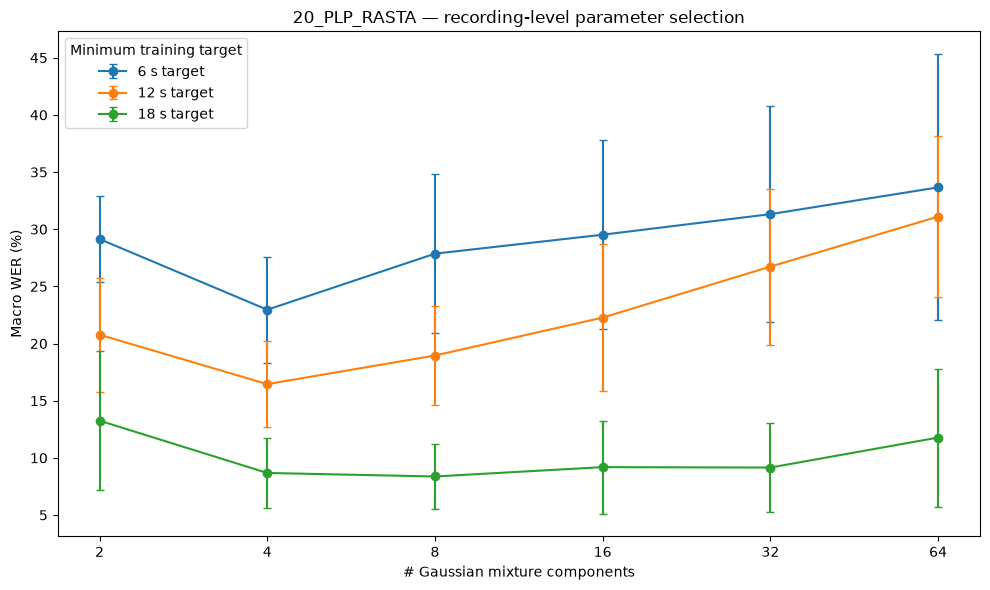

In [27]:
if RUN_STAGE_B:

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    for target_seconds in TRAINING_DURATIONS:

        subset = (
            stage_b_summary[
                stage_b_summary[
                    "training_seconds_target"
                ] == target_seconds
            ]
            .sort_values(
                "n_components"
            )
        )

        ax.errorbar(
            subset[
                "n_components"
            ],
            subset[
                "WER_mean_percent"
            ],
            yerr=subset[
                "WER_std_percent"
            ],
            marker="o",
            capsize=3,
            label=f"{target_seconds} s target",
        )

    ax.set_xscale(
        "log",
        base=2,
    )

    ax.set_xticks(
        N_COMPONENTS_GRID
    )

    ax.set_xticklabels(
        [
            str(M)
            for M in N_COMPONENTS_GRID
        ]
    )

    ax.set(
        title=(
            f"{ROBUST_FEATURE} — recording-level parameter selection"
        ),
        xlabel="# Gaussian mixture components",
        ylabel="Macro WER (%)",
    )

    ax.legend(
        title="Minimum training target"
    )

    plt.tight_layout()
    plt.show()

## 17. Empirical best and one-standard-error recommendation

Two final configurations are reported.

### Empirical best

The literal minimum mean recording-level WER across all tested duration/model-order combinations.

### Parsimonious recommendation

Use the **one-standard-error rule**:

1. calculate `best mean WER + SE of the best`;
2. retain every configuration below that limit;
3. choose the smallest `M`;
4. if several durations remain for that `M`, choose the lower mean WER, then the longer target duration.

This preserves performance while avoiding unnecessary model complexity.

In [28]:
if RUN_STAGE_B:

    robust_empirical_best = (
        stage_b_summary
        .sort_values(
            [
                "WER_mean",
                "WER_std",
                "n_components",
            ]
        )
        .iloc[0]
    )

    robust_best_mean = float(
        robust_empirical_best[
            "WER_mean"
        ]
    )

    robust_best_se = float(
        robust_empirical_best[
            "WER_se"
        ]
    )

    robust_one_se_limit = (
        robust_best_mean
        + robust_best_se
    )

    robust_one_se_candidates = (
        stage_b_summary[
            stage_b_summary[
                "WER_mean"
            ]
            <= robust_one_se_limit
        ]
        .copy()
        .sort_values(
            [
                "n_components",
                "WER_mean",
                "training_seconds_target",
            ],
            ascending=[
                True,
                True,
                False,
            ],
        )
        .reset_index(drop=True)
    )

    robust_recommended = (
        robust_one_se_candidates
        .iloc[0]
    )

    robust_empirical_best_table = (
        pd.DataFrame([
            {
                "feature":
                    ROBUST_FEATURE,
                "training_seconds_target":
                    int(
                        robust_empirical_best[
                            "training_seconds_target"
                        ]
                    ),
                "n_components":
                    int(
                        robust_empirical_best[
                            "n_components"
                        ]
                    ),
                "WER_mean_percent":
                    float(
                        robust_empirical_best[
                            "WER_mean_percent"
                        ]
                    ),
                "WER_std_percent":
                    float(
                        robust_empirical_best[
                            "WER_std_percent"
                        ]
                    ),
                "WER_se_percent":
                    float(
                        robust_empirical_best[
                            "WER_se_percent"
                        ]
                    ),
                "CI95_low_percent":
                    float(
                        robust_empirical_best[
                            "CI95_low_percent"
                        ]
                    ),
                "CI95_high_percent":
                    float(
                        robust_empirical_best[
                            "CI95_high_percent"
                        ]
                    ),
            }
        ])
    )

    robust_recommended_table = (
        pd.DataFrame([
            {
                "feature":
                    ROBUST_FEATURE,
                "training_seconds_target":
                    int(
                        robust_recommended[
                            "training_seconds_target"
                        ]
                    ),
                "n_components":
                    int(
                        robust_recommended[
                            "n_components"
                        ]
                    ),
                "WER_mean_percent":
                    float(
                        robust_recommended[
                            "WER_mean_percent"
                        ]
                    ),
                "WER_std_percent":
                    float(
                        robust_recommended[
                            "WER_std_percent"
                        ]
                    ),
                "selection_rule":
                    (
                        "smallest M within one SE of robust empirical minimum"
                    ),
            }
        ])
    )

    print("Robust empirical best")
    display(
        robust_empirical_best_table.round(4)
    )

    print(
        "One-SE limit:",
        round(
            robust_one_se_limit
            * 100,
            4,
        ),
        "% WER",
    )

    print("One-SE candidates")
    display(
        robust_one_se_candidates[
            [
                "training_seconds_target",
                "n_components",
                "WER_mean_percent",
                "WER_std_percent",
                "WER_se_percent",
            ]
        ].round(4)
    )

    print("Robust recommended configuration")
    display(
        robust_recommended_table.round(4)
    )

Robust empirical best


,feature,training_seconds_target,n_components,WER_mean_percent,WER_std_percent,WER_se_percent,CI95_low_percent,CI95_high_percent
0,20_PLP_RASTA,18,8,8.3722,2.8385,0.8976,6.3417,10.4027


One-SE limit: 9.2698 % WER
One-SE candidates


,training_seconds_target,n_components,WER_mean_percent,WER_std_percent,WER_se_percent
0,18,4,8.6811,3.0764,0.9728
1,18,8,8.3722,2.8385,0.8976
2,18,16,9.1909,4.0593,1.2837
3,18,32,9.1537,3.8940,1.2314


Robust recommended configuration


,feature,training_seconds_target,n_components,WER_mean_percent,WER_std_percent,selection_rule
0,20_PLP_RASTA,18,4,8.6811,3.0764,smallest M within one SE of robust empirical m...


## 18. Per-species performance of the robust recommended configuration

Macro WER can conceal a difficult species behind several easy ones. This table identifies which classes
remain problematic when recordings are genuinely unseen.

In [29]:
if RUN_STAGE_B:

    final_target = int(
        robust_recommended[
            "training_seconds_target"
        ]
    )

    final_M = int(
        robust_recommended[
            "n_components"
        ]
    )

    robust_recommended_species = (
        stage_b_per_species[
            (
                stage_b_per_species[
                    "training_seconds_target"
                ] == final_target
            )
            & (
                stage_b_per_species[
                    "n_components"
                ] == final_M
            )
        ]
        .groupby(
            [
                "code",
                "species",
            ],
            as_index=False,
        )
        .agg(
            error_mean=(
                "error_rate",
                "mean",
            ),
            error_std=(
                "error_rate",
                "std",
            ),
            validation_calls_mean=(
                "n_validation_calls",
                "mean",
            ),
            training_seconds_actual_mean=(
                "training_seconds_actual",
                "mean",
            ),
            train_recordings_mean=(
                "n_train_recordings",
                "mean",
            ),
            validation_recordings_mean=(
                "n_validation_recordings",
                "mean",
            ),
        )
    )

    robust_recommended_species[
        "error_mean_percent"
    ] = (
        robust_recommended_species[
            "error_mean"
        ]
        * 100
    )

    robust_recommended_species[
        "error_std_percent"
    ] = (
        robust_recommended_species[
            "error_std"
        ]
        * 100
    )

    display(
        robust_recommended_species[
            [
                "code",
                "species",
                "error_mean_percent",
                "error_std_percent",
                "training_seconds_actual_mean",
                "train_recordings_mean",
                "validation_recordings_mean",
            ]
        ].round(4)
    )

,code,species,error_mean_percent,error_std_percent,training_seconds_actual_mean,train_recordings_mean,validation_recordings_mean
0,f01,Boana alfaroi,0.0000,0.0000,19.000,2.0,3.0
1,f02,Dendropsophus bifurcus,6.4329,6.9185,19.432,4.6,5.4
2,f03,Boana cinerascens,9.5367,14.4607,20.522,2.0,6.0
3,f04,Pristimantis conspicillatus,21.6149,23.8809,20.116,2.6,6.4
4,f05,Leptodactylus discodactylus,6.9756,5.3389,47.560,1.0,2.0
5,f06,Osteocephalus fuscifacies,0.0000,0.0000,18.716,3.8,1.2
6,f07,Boana lanciformis,26.7042,24.0212,20.922,2.8,4.2
7,f08,Rhinella margaritifera,6.8658,14.7529,21.782,2.1,4.9
8,f10,Engystomops petersi,0.0000,0.0000,22.280,2.5,9.5


## 19. Compare call-level, earlier robustness check, paper, and robust final model

This table keeps the different claims separate.

- The **paper result** is the published methodological reference.
- The **call-level result** from notebook 06 is retained as an optimistic within-recording estimate.
- The earlier fixed `18 s + M=32 PLP-RASTA` recording-level check is included when its saved output is
  available.
- The **06B recommendation** is the configuration to carry forward.

In [30]:
comparison_rows = [
    {
        "source": "PAPER",
        "validation_scope": (
            "published call-segment protocol"
        ),
        "feature": "20_mFCC",
        "training_target_seconds": np.nan,
        "n_components": 64,
        "WER_mean_percent": np.nan,
        "interpretation": (
            "Published reference; paper reports m-FCC as preferred."
        ),
    },
    {
        "source": "06_CALL_LEVEL_BEST",
        "validation_scope": "call-level split",
        "feature": "20_PLP_RASTA",
        "training_target_seconds": 18,
        "n_components": 32,
        "WER_mean_percent": 0.09860949540346953,
        "interpretation": (
            "Optimistic because calls from the same WAV may cross partitions."
        ),
    },
]

if PREVIOUS_RECORDING_SUMMARY_PATH.exists():

    previous_recording = (
        pd.read_csv(
            PREVIOUS_RECORDING_SUMMARY_PATH
        )
        .iloc[0]
    )

    comparison_rows.append({
        "source": "06_RECORDING_CHECK",
        "validation_scope": "recording-level split",
        "feature": str(
            previous_recording.get(
                "feature",
                "20_PLP_RASTA",
            )
        ),
        "training_target_seconds": float(
            previous_recording.get(
                "training_seconds",
                18,
            )
        ),
        "n_components": int(
            previous_recording.get(
                "n_components",
                32,
            )
        ),
        "WER_mean_percent": float(
            previous_recording[
                "WER_mean_percent"
            ]
        ),
        "interpretation": (
            "Earlier robustness check at the call-level winner."
        ),
    })

if RUN_STAGE_B:

    comparison_rows.append({
        "source": "06B_ROBUST_RECOMMENDED",
        "validation_scope": "recording-level split",
        "feature": ROBUST_FEATURE,
        "training_target_seconds": int(
            robust_recommended[
                "training_seconds_target"
            ]
        ),
        "n_components": int(
            robust_recommended[
                "n_components"
            ]
        ),
        "WER_mean_percent": float(
            robust_recommended[
                "WER_mean_percent"
            ]
        ),
        "interpretation": (
            "Recommended configuration after robust feature and parameter selection."
        ),
    })

paper_call_robust_comparison = pd.DataFrame(
    comparison_rows
)

display(
    paper_call_robust_comparison.round(4)
)

,source,validation_scope,feature,training_target_seconds,n_components,WER_mean_percent,interpretation
0,PAPER,published call-segment protocol,20_mFCC,NaN,64,NaN,Published reference; paper reports m-FCC as pr...
1,06_CALL_LEVEL_BEST,call-level split,20_PLP_RASTA,18.0,32,0.0986,Optimistic because calls from the same WAV may...
2,06_RECORDING_CHECK,recording-level split,20_PLP_RASTA,18.0,32,8.8724,Earlier robustness check at the call-level win...
3,06B_ROBUST_RECOMMENDED,recording-level split,20_PLP_RASTA,18.0,4,8.6811,Recommended configuration after robust feature...


## 20. Export the robust final configuration

Notebook 07 should read **this** file, not the older call-level `selected_configuration.json`.

The robust selection JSON explicitly records:

- winning feature;
- empirical best configuration;
- parsimonious recommendation;
- recording-level validation rule;
- paper reference;
- known limitation that grouped WAVs cause target-duration overshoot.

In [31]:
if RUN_STAGE_B:

    robust_selection = {
        "selection_notebook":
            "06B_robust_model_selection",
        "validation_unit":
            "source_wav",
        "group_column":
            "wav",
        "feature":
            ROBUST_FEATURE,
        "feature_dimensions":
            int(
                EXPECTED_DIMS[
                    ROBUST_FEATURE
                ]
            ),
        "classes":
            list(
                USABLE_CODES
            ),
        "excluded_class":
            "f09",
        "n_repeats":
            N_REPEATS,
        "feature_comparison_target_seconds":
            FEATURE_COMPARISON_SECONDS,
        "training_targets_tested":
            list(
                TRAINING_DURATIONS
            ),
        "n_components_tested":
            list(
                N_COMPONENTS_GRID
            ),
        "empirical_best": {
            "training_seconds_target":
                int(
                    robust_empirical_best[
                        "training_seconds_target"
                    ]
                ),
            "n_components":
                int(
                    robust_empirical_best[
                        "n_components"
                    ]
                ),
            "WER_mean":
                float(
                    robust_empirical_best[
                        "WER_mean"
                    ]
                ),
            "WER_std":
                float(
                    robust_empirical_best[
                        "WER_std"
                    ]
                ),
            "WER_se":
                float(
                    robust_empirical_best[
                        "WER_se"
                    ]
                ),
        },
        "recommended_parsimonious": {
            "training_seconds_target":
                int(
                    robust_recommended[
                        "training_seconds_target"
                    ]
                ),
            "n_components":
                int(
                    robust_recommended[
                        "n_components"
                    ]
                ),
            "WER_mean":
                float(
                    robust_recommended[
                        "WER_mean"
                    ]
                ),
            "WER_std":
                float(
                    robust_recommended[
                        "WER_std"
                    ]
                ),
            "selection_rule":
                (
                    "smallest M within one SE of robust empirical minimum"
                ),
        },
        "paper_reference": {
            "feature":
                "20_mFCC",
            "n_components":
                64,
            "note":
                (
                    "published result retained as reference; "
                    "not forced onto robust recovered-data model"
                ),
        },
        "limitations": [
            (
                "training seconds are minimum targets because "
                "whole WAV recordings are grouped"
            ),
            (
                "some species have few independent source WAVs, "
                "which increases uncertainty"
            ),
            (
                "PLP-RASTA and m-FCC implementations are reconstructed "
                "from incompletely specified paper details"
            ),
        ],
    }

    print(
        json.dumps(
            robust_selection,
            indent=2,
        )
    )

{
  "selection_notebook": "06B_robust_model_selection",
  "validation_unit": "source_wav",
  "group_column": "wav",
  "feature": "20_PLP_RASTA",
  "feature_dimensions": 20,
  "classes": [
    "f01",
    "f02",
    "f03",
    "f04",
    "f05",
    "f06",
    "f07",
    "f08",
    "f10"
  ],
  "excluded_class": "f09",
  "n_repeats": 10,
  "feature_comparison_target_seconds": 12,
  "training_targets_tested": [
    6,
    12,
    18
  ],
  "n_components_tested": [
    2,
    4,
    8,
    16,
    32,
    64
  ],
  "empirical_best": {
    "training_seconds_target": 18,
    "n_components": 8,
    "WER_mean": 0.08372192952975063,
    "WER_std": 0.028384956413037645,
    "WER_se": 0.008976111354980212
  },
  "recommended_parsimonious": {
    "training_seconds_target": 18,
    "n_components": 4,
    "WER_mean": 0.08681112180369452,
    "WER_std": 0.030763664707736303,
    "selection_rule": "smallest M within one SE of robust empirical minimum"
  },
  "paper_reference": {
    "feature": "20_mFCC

## 21. Save all robustness-selection outputs

In [32]:
if RUN_STAGE_A:

    stage_a_summary.to_csv(
        RESULTS_DIR
        / "stage_a_feature_summary.csv",
        index=False,
    )

    best_per_feature.to_csv(
        RESULTS_DIR
        / "stage_a_best_per_feature.csv",
        index=False,
    )

    stage_a_per_species.to_csv(
        RESULTS_DIR
        / "stage_a_per_species.csv",
        index=False,
    )

    if STORE_CALL_PREDICTIONS:
        stage_a_predictions.to_csv(
            RESULTS_DIR
            / "stage_a_call_predictions.csv",
            index=False,
        )

if RUN_STAGE_B:

    stage_b_summary.to_csv(
        RESULTS_DIR
        / "stage_b_parameter_summary.csv",
        index=False,
    )

    robust_parameter_table.to_csv(
        RESULTS_DIR
        / "stage_b_parameter_table_percent.csv",
    )

    stage_b_per_species.to_csv(
        RESULTS_DIR
        / "stage_b_per_species.csv",
        index=False,
    )

    robust_empirical_best_table.to_csv(
        RESULTS_DIR
        / "robust_empirical_best.csv",
        index=False,
    )

    robust_recommended_table.to_csv(
        RESULTS_DIR
        / "robust_recommended_configuration.csv",
        index=False,
    )

    robust_recommended_species.to_csv(
        RESULTS_DIR
        / "robust_recommended_per_species.csv",
        index=False,
    )

    if STORE_CALL_PREDICTIONS:
        stage_b_predictions.to_csv(
            RESULTS_DIR
            / "stage_b_call_predictions.csv",
            index=False,
        )

    with open(
        RESULTS_DIR
        / "selected_robust_configuration.json",
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            robust_selection,
            f,
            indent=2,
        )

split_audit.to_csv(
    RESULTS_DIR
    / "recording_split_audit.csv",
    index=False,
)

split_diversity.to_csv(
    RESULTS_DIR
    / "recording_split_diversity.csv",
    index=False,
)

paper_call_robust_comparison.to_csv(
    RESULTS_DIR
    / "paper_call_robust_comparison.csv",
    index=False,
)

print("Saved outputs:")

for path in sorted(
    RESULTS_DIR.iterdir()
):
    print(
        f"  {path.name:<42} "
        f"{path.stat().st_size / 1e6:>8.3f} MB"
    )

Saved outputs:
  paper_call_robust_comparison.csv              0.001 MB
  recording_split_audit.csv                     0.017 MB
  recording_split_diversity.csv                 0.000 MB
  robust_empirical_best.csv                     0.000 MB
  robust_recommended_configuration.csv          0.000 MB
  robust_recommended_per_species.csv            0.001 MB
  selected_robust_configuration.json            0.001 MB
  stage_a_best_per_feature.csv                  0.001 MB
  stage_a_call_predictions.csv                 20.871 MB
  stage_a_feature_summary.csv                   0.007 MB
  stage_a_feature_wer_by_repeat.csv             0.013 MB
  stage_a_per_species.csv                       0.192 MB
  stage_b_call_predictions.csv                 16.560 MB
  stage_b_parameter_summary.csv                 0.005 MB
  stage_b_parameter_table_percent.csv           0.000 MB
  stage_b_parameter_wer_by_repeat.csv           0.011 MB
  stage_b_per_species.csv                       0.146 MB


## 22. Interpretation and next step

After this notebook finishes, the project should use the **06B robust recommendation** as the modelling
choice for later detector work.

### What should be reported

1. **Paper:** the authors report 20 m-FCC and a high-order GMM configuration as their preferred setup.
2. **Initial recovered-data result:** call-level splits strongly favored PLP-RASTA and produced extremely
   low WER.
3. **Leakage robustness result:** separating complete recordings caused a large performance drop,
   showing that call-level validation was optimistic.
4. **Robust final result:** this notebook reselects both the feature representation and GMM parameters
   using unseen-recording validation.

### Next notebook

`07_final_detector_calibration.ipynb`

It should:

- load `data/processed/robust_model_selection/selected_robust_configuration.json`;
- use the robust feature representation;
- create a **recording-level leakage-free TRAIN/CALIBRATION split**;
- fit one frozen GMM per species;
- compute held-out one-vs-all LLR scores;
- derive per-species ROC curves and thresholds;
- serialize the GMMs and thresholds together.

The older m-FCC thresholds must not be reused if the robust winning representation is different.